In [1]:
#manipulação de dados
import pandas as pd
import numpy as np

#deepcopy
from copy import deepcopy

#modelos que iremos aplicar nos dados
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from tabpfn import TabPFNClassifier

#obtenção do grid e randomized search
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, FixedThresholdClassifier
from sklearn.metrics import roc_curve, precision_recall_curve, auc, classification_report, confusion_matrix
from sklearn.calibration import calibration_curve

#visualização de dados
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

#definição de seed para reprodutibilidade
seed = 42

In [2]:
#Import da base de treino e teste
df_train = pd.read_csv("../datasets/dados_treino.csv",
                        encoding='latin1', sep=",")
df_test = pd.read_csv("../datasets/dados_teste.csv",
                        encoding='latin1', sep=",")

In [3]:
#Separação das bases entre X_train, X_test, y_train, y_test
X_train = df_train.drop(columns = "obito")
y_train = df_train.obito

X_test = df_test.drop(columns = "obito")
y_test = df_test.obito

In [4]:
y_train.value_counts(normalize = True)

obito
0.0    0.843917
1.0    0.156083
Name: proportion, dtype: float64

In [5]:
y_test.value_counts(normalize = True)

obito
0.0    0.843686
1.0    0.156314
Name: proportion, dtype: float64

Grid Search faz a permutação dos valores

In [6]:
#modelo e dicionário de busca
lr = LogisticRegression(random_state = seed)
lr_dict = {
    'penalty': ['l2', None],                 # tipo de regularização a ser aplicada (L2 ou sem regularização)
    'C': np.logspace(-3, 3, 10),              # força da regularização (quanto menor o valor, mais forte a regularização)
}

#criação do random search
lr_gs = GridSearchCV(estimator=lr,          #modelo
                      param_grid=lr_dict,   #dicionário com a lista dos hiperparâmetros
                      scoring='roc_auc',    # métrica de avaliação
                      cv=5,                 # validação cruzada 5-fold
                      n_jobs=-1             # usar todos os núcleos
                      )

#fit do random search
lr_gs.fit(X_train, y_train)

#print dos melhores hiperparametros
print("Hiperparametros do lr: ", lr_gs.best_params_)

#criação do modelo final
lr = lr_gs.best_estimator_

Hiperparametros do lr:  {'C': np.float64(0.1), 'penalty': 'l2'}


c:\Users\olive\anaconda3\envs\LABDAPS\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Random Search faz o treino sorteando aleatoriamente os valores possíveis e podemos dar um valor de iterações para limitar

In [7]:
# Modelo e dicionário de busca
rf = RandomForestClassifier(random_state=seed)
rf_dict = {
    'n_estimators': np.arange(200, 501, 100),           # número de árvores, de 200 a 500 com passo de 100
    'max_depth': np.arange(5, 15, 1),                   # profundidade máxima, de 5 a 14
    'min_samples_split': np.geomspace(0.005, 0.05, 5),  # fração mínima de amostras para dividir um nó (escala geométrica)
    'min_samples_leaf': [5, 15, 25],                    # número mínimo de amostras em cada folha
    'max_features': ['sqrt', 'log2', None],             # número máximo de features consideradas por divisão
}

# Criação do random search
rf_rs = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_dict,
    n_iter=20,              # número de combinações testadas
    scoring='roc_auc',      # métrica de avaliação
    cv=5,                   # validação cruzada 5-fold
    random_state=seed,      # seed para garantir reprodutibilidade
    n_jobs=-1               # usar todos os núcleos
)

# Fit do random search
rf_rs.fit(X_train, y_train)

# Print dos melhores hiperparâmetros
print("Hiperparâmetros do rf: ", rf_rs.best_params_)

# Criação do modelo final
rf = rf_rs.best_estimator_


Hiperparâmetros do rf:  {'n_estimators': np.int64(300), 'min_samples_split': np.float64(0.015811388300841896), 'min_samples_leaf': 15, 'max_features': None, 'max_depth': np.int64(9)}


In [8]:
# Modelo e dicionário de busca
xgb = XGBClassifier(
    objective='binary:logistic',  # problema de classificação binária
    random_state=seed
    )

xgb_dict = {
    'n_estimators': np.arange(200, 501, 100),           # número de árvores, de 100 a 500 com passo de 100
    'max_depth': np.arange(3, 11, 1),                   # profundidade máxima da árvore, de 3 a 10
    'learning_rate': np.logspace(-2, -0.7, 4),          # taxa de aprendizado, de 0.01 a 0.2 em escala logarítmica
    'subsample': np.linspace(0.6, 1.0, 3),              # proporção de amostras usadas por árvore
    'colsample_bytree': np.linspace(0.6, 1.0, 3),       # proporção de features usadas por árvore
    'gamma': np.linspace(0, 0.3, 4),                    # regularização por redução mínima da perda
    'reg_alpha': np.logspace(-3, 0, 4),                 # regularização L1, de 0.001 a 1
    'reg_lambda': np.linspace(1, 2, 3)                  # regularização L2, de 1 a 2
}

# Criação do random search
xgb_rs = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_dict,
    n_iter=20,              # número de combinações testadas
    scoring='roc_auc',      # métrica de avaliação
    cv=5,                   # validação cruzada 5-fold
    random_state=seed,      # seed para garantir reprodutibilidade
    n_jobs=-1               # usar todos os núcleos
)

# Fit do random search
xgb_rs.fit(X_train, y_train)

# Print dos melhores hiperparâmetros
print("Hiperparâmetros do xgb: ", xgb_rs.best_params_)

# Criação do modelo final
xgb = xgb_rs.best_estimator_


Hiperparâmetros do xgb:  {'subsample': np.float64(0.8), 'reg_lambda': np.float64(2.0), 'reg_alpha': np.float64(1.0), 'n_estimators': np.int64(500), 'max_depth': np.int64(3), 'learning_rate': np.float64(0.02712272579332028), 'gamma': np.float64(0.0), 'colsample_bytree': np.float64(1.0)}


In [9]:
#Cria a probabilidade de obito para a base de teste
y_prob_lr = lr.predict_proba(X_test)[:,1]
y_prob_rf = rf.predict_proba(X_test)[:,1]
y_prob_xgb = xgb.predict_proba(X_test)[:,1]

# Calcula as curvas ROC e AUC para cada modelo
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

In [10]:
# Cria a figura Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=fpr_lr, y=tpr_lr,
    mode='lines',
    name=f'Logistic Regression (AUC = {roc_auc_lr:.2f})',
    line=dict(color='blue')
))

fig.add_trace(go.Scatter(
    x=fpr_rf, y=tpr_rf,
    mode='lines',
    name=f'Random Forest (AUC = {roc_auc_rf:.2f})',
    line=dict(color='green')
))

fig.add_trace(go.Scatter(
    x=fpr_xgb, y=tpr_xgb,
    mode='lines',
    name=f'XGBoost (AUC = {roc_auc_xgb:.2f})',
    line=dict(color='orange')
))

# Linha de referência
fig.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1],
    mode='lines',
    line=dict(color='red', dash='dash'),
    showlegend=False
))

# Layout
fig.update_layout(
    title='Curva ROC - Comparação de Modelos',
    xaxis_title='Taxa de Falso Positivo (FPR)',
    yaxis_title='Taxa de Verdadeiro Positivo (TPR)',
    width=900,
    height=600
)

fig.show()

In [11]:
# Calcula Precision e Recall para cada modelo
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob_lr)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf)
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)

# Calcula AUC da curva Precision-Recall
pr_auc_lr = auc(recall_lr, precision_lr)
pr_auc_rf = auc(recall_rf, precision_rf)
pr_auc_xgb = auc(recall_xgb, precision_xgb)

# Cria a figura Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=recall_lr, y=precision_lr,
    mode='lines',
    name=f'Logistic Regression (AUC = {pr_auc_lr:.2f})',
    line=dict(color='blue')
))

fig.add_trace(go.Scatter(
    x=recall_rf, y=precision_rf,
    mode='lines',
    name=f'Random Forest (AUC = {pr_auc_rf:.2f})',
    line=dict(color='green')
))

fig.add_trace(go.Scatter(
    x=recall_xgb, y=precision_xgb,
    mode='lines',
    name=f'XGBoost (AUC = {pr_auc_xgb:.2f})',
    line=dict(color='orange')
))

# Layout
fig.update_layout(
    title='Curva Precision-Recall - Comparação de Modelos',
    xaxis_title='Recall (Sensibilidade)',
    yaxis_title='Precision (Precisão)',
    width=900,
    height=600
)

fig.show()


In [12]:
# Obtenção dos parametros para a curva de calibração
prob_true_lr, prob_pred_lr = calibration_curve(y_test, y_prob_lr, n_bins=10, strategy='uniform')
prob_true_rf, prob_pred_rf = calibration_curve(y_test, y_prob_rf, n_bins=10, strategy='uniform')
prob_true_xgb, prob_pred_xgb = calibration_curve(y_test, y_prob_xgb, n_bins=10, strategy='uniform')

In [13]:
# Cria a figura Plotly
fig = go.Figure()

# Logistic Regression
fig.add_trace(go.Scatter(
    x=prob_pred_lr, y=prob_true_lr,
    mode='lines+markers',
    name='Logistic Regression',
    line=dict(color='blue')
))

# Random Forest
fig.add_trace(go.Scatter(
    x=prob_pred_rf, y=prob_true_rf,
    mode='lines+markers',
    name='Random Forest',
    line=dict(color='green')
))

# XGBoost
fig.add_trace(go.Scatter(
    x=prob_pred_xgb, y=prob_true_xgb,
    mode='lines+markers',
    name='XGBoost',
    line=dict(color='orange')
))

# Linha de referência (modelo perfeitamente calibrado)
fig.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1],
    mode='lines',
    line=dict(color='red', dash='dash'),
    showlegend=False
))

# Layout
fig.update_layout(
    title='Curva de Calibração - Comparação de Modelos',
    xaxis_title='Probabilidade Prevista',
    yaxis_title='Frequência Observada',
    width=900,
    height=600
)

fig.show()


In [14]:
# Exemplo com o melhor modelo - XGBoost
df_pred = pd.DataFrame({
    "probabilidade": y_prob_xgb,
    "classe_real": y_test
})

fig = px.histogram(
    df_pred,
    x="probabilidade",
    color="classe_real",
    nbins=50,
    barmode="overlay",
    histnorm="percent",  # normaliza para comparar porcentagens
    color_discrete_map={0: "blue", 1: "red"}
)

fig.update_layout(
    title="Distribuição das Probabilidades Previstas - XGBoost",
    xaxis_title="Probabilidade Prevista de Óbito",
    yaxis_title="Porcentagem de Observações",
    legend_title="Classe Real",
    width=900,
    height=500
)

fig.show()

In [15]:
# Exemplo com o melhor modelo - XGBoost
df_pred = pd.DataFrame({
    "probabilidade": y_prob_xgb,
    "classe_real": y_test
})

fig = px.histogram(
    df_pred,
    x="probabilidade",
    color="classe_real",
    nbins=50,
    barmode="overlay",
    histnorm="percent",  # normaliza para comparar porcentagens
    color_discrete_map={0: "blue", 1: "red"}
)

fig.update_layout(
    title="Distribuição das Probabilidades Previstas - XGBoost",
    xaxis_title="Probabilidade Prevista de Óbito",
    yaxis_title="Porcentagem de Observações",
    legend_title="Classe Real",
    width=900,
    height=500
)

fig.show()

In [16]:
#obtenção da predição do xgboost
y_pred_xgb = xgb.predict(X_test)

#criação do classification report
print(classification_report(y_test, y_pred_xgb,
      target_names=['Não Óbito', 'Óbito']))

              precision    recall  f1-score   support

   Não Óbito       0.87      0.99      0.93      2051
       Óbito       0.79      0.21      0.33       380

    accuracy                           0.87      2431
   macro avg       0.83      0.60      0.63      2431
weighted avg       0.86      0.87      0.83      2431



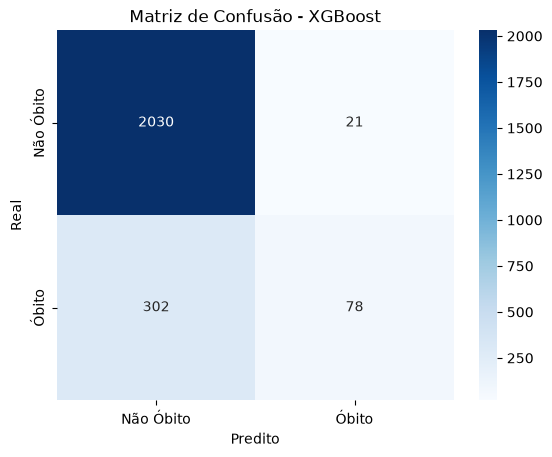

In [17]:
#cria e plota a matriz de confusão
cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Não Óbito', 'Óbito'], yticklabels=['Não Óbito', 'Óbito'])
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão - XGBoost')
plt.show()

Mudar o limiar de definição de classificação, poderia fazer manualmente com o resultado do `predict_proba`, mas existe uma biblioteca que facilita o processo

In [18]:
#Cria uma copia do xgboost, para não sobescrevê-lo
xgb_novo = deepcopy(xgb)

#Criação do novo modelo
xgb_novo = FixedThresholdClassifier(xgb_novo, threshold=0.3, response_method="predict_proba").fit(X_train, y_train)

In [21]:
#obtenção da predição do xgboost
y_pred_xgb_novo = xgb_novo.predict(X_test)

#criação do classification report
print(classification_report(y_test, xgb.predict(X_test),
      target_names=['Não Óbito', 'Óbito']))

print(classification_report(y_test, y_pred_xgb_novo,
      target_names=['Não Óbito', 'Óbito']))

              precision    recall  f1-score   support

   Não Óbito       0.87      0.99      0.93      2051
       Óbito       0.79      0.21      0.33       380

    accuracy                           0.87      2431
   macro avg       0.83      0.60      0.63      2431
weighted avg       0.86      0.87      0.83      2431

              precision    recall  f1-score   support

   Não Óbito       0.89      0.93      0.91      2051
       Óbito       0.53      0.41      0.46       380

    accuracy                           0.85      2431
   macro avg       0.71      0.67      0.69      2431
weighted avg       0.84      0.85      0.84      2431



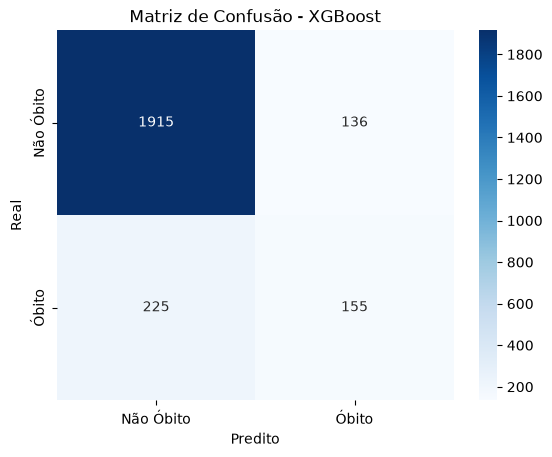

In [20]:
#cria e plota a matriz de confusão
cm = confusion_matrix(y_test, y_pred_xgb_novo)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Não Óbito', 'Óbito'], yticklabels=['Não Óbito', 'Óbito'])
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão - XGBoost')
plt.show()